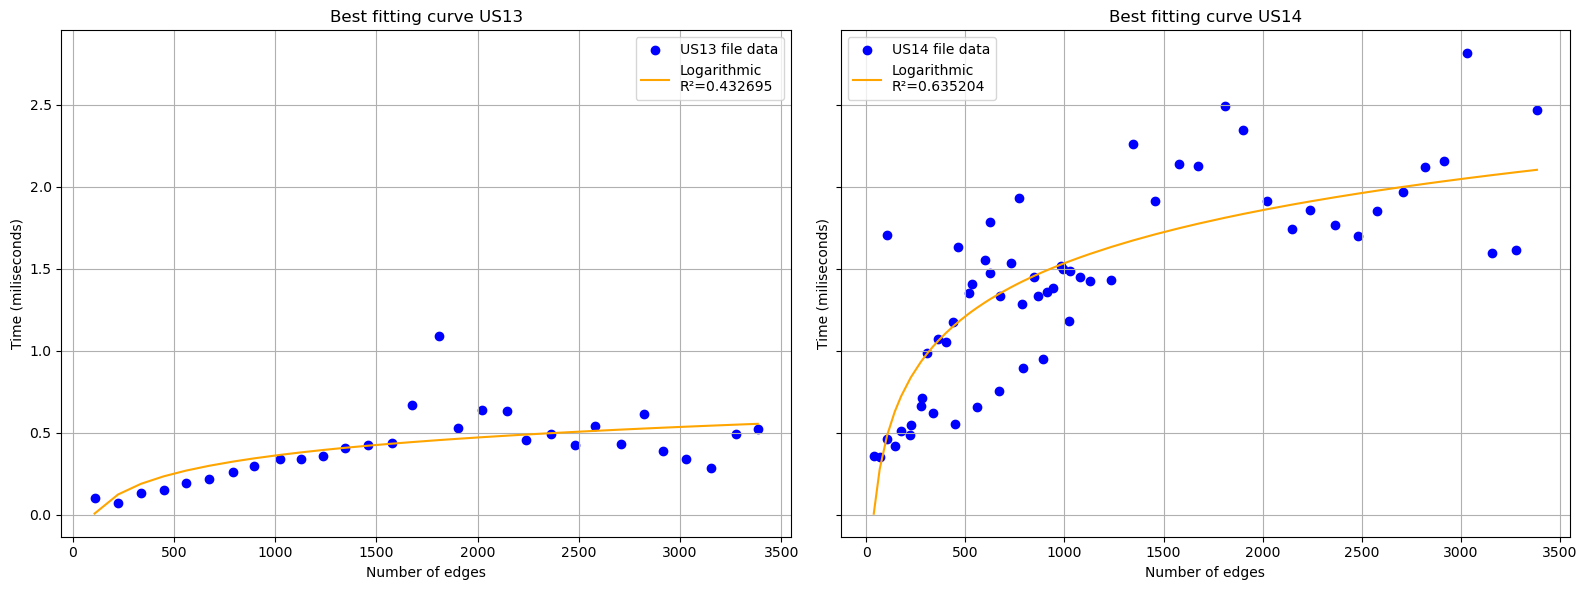

=========== US13 Curve ===========
Best fitting curve for US13 results: Logarithmic O(log(n))
R² = 0.432695
Residual Sum of Squares (RSS/SQE) = 0.700452



=========== US14 Curve ===========
Best fitting curve for US14 results: Logarithmic O(log(n))
R² = 0.635204
Residual Sum of Squares (RSS/SQE) = 7.704038


In [59]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

data13 = pd.read_csv("us13_results_us30.csv", sep=";", decimal=",")
data14 = pd.read_csv("us14_results_us30.csv", sep=";", decimal=",")

group13 = data13.groupby("size")["time"].mean().reset_index()
x13 = group13["size"].values
y13 = group13["time"].values

group14 = data14.groupby("size")["time"].mean().reset_index()
x14 = group14["size"].values
y14 = group14["time"].values

def bestFit(x, y):
    functions = {"Linear O(n)": x,
                 f"Quadratic O(n^2)": x ** 2,
                 f"Cubic O(n^3)": x ** 3,
                 "Logarithmic O(log(n))": np.log(x)}

    bestR2 = -1
    bestFit = None
    function = ""
    bestSQE = 0
    bestSxx, bestSyy, bestSxy
    
    for (name, func) in functions.items():
        meanX = np.mean(func)
        meanY = np.mean(y)
        Sxx = 0
        Sxy = 0
        Syy = 0
        
        for index in range(len(x)):
            Sxx += (func[index] - meanX) ** 2
        for valueY in y:
            Syy += (valueY - meanY) ** 2
        for index in range(len(x)):
            Sxy += (func[index] - meanX) * (y[index] - meanY)
        
        r2 = (Sxy / math.sqrt(Sxx * Syy)) ** 2
        beta1 = Sxy / Sxx
        beta0 = meanY - (beta1 * meanX)
        fitY = beta0 + (beta1 * func)
        sqe = Syy - (Sxy ** 2 / Sxx)
        
        if r2 > bestR2:
            bestR2 = r2
            bestFit = fitY
            function = name
            bestSQE = sqe
            bestSxx = Sxx
            bestSyy = Syy
            bestSxy = Sxy

    return bestR2, bestFit, function, bestSQE, bestSxx, bestSyy, bestSxy


r2_13, fit13, function13, sqe13 = bestFit(x13,y13)
r2_14, fit14, function14, sqe14 = bestFit(x14,y14)

fig, (us13, us14) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

us13.scatter(x13, y13, color="blue", label="US13 file data")
us13.plot(x13, fit13, color="orange", label=f'{function}\nR²={r2_13:.6f}')
us13.set_xlabel("Number of edges")
us13.set_ylabel("Time (miliseconds)")
us13.set_title("Best fitting curve US13")
us13.grid(True)
us13.legend()

us14.scatter(x14, y14, color="blue", label="US14 file data")
us14.plot(x14, fit14, color="orange", label=f'{function}\nR²={r2_14:.6f}')
us14.set_xlabel("Number of edges")
us14.set_ylabel("Time (miliseconds)")
us14.set_title("Best fitting curve US14")
us14.grid(True)
us14.legend()


plt.tight_layout()
plt.show()

print('=========== US13 Curve ===========')
print(f'Best fitting curve for US13 results: {function13}')
print(f'R² = {r2_13:.6f}')
print(f'Residual Sum of Squares (RSS/SQE) = {sqe13:.6f}')

print('\n\n')

print('=========== US14 Curve ===========')
print(f'Best fitting curve for US14 results: {function14}')
print(f'R² = {r2_14:.6f}')
print(f'Residual Sum of Squares (RSS/SQE) = {sqe14:.6f}')